In [2]:
from shapely import MultiLineString, LineString
import geopandas as gpd

wyspy = gpd.read_file("dane/fw2.geojson")

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

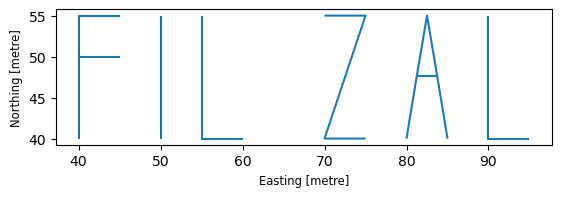

In [36]:
#ZADANIE A)

line1 = LineString([
    (40, 40),(40, 50),(40, 55),(45, 55)])

line2 = LineString([
    (40, 50),(45, 50)])

line3 = LineString([
    (50, 40),(50, 55)])

line4 = LineString([
    (55, 55),(55, 40),(60, 40)])

line5 = LineString([
    (70, 55),(75, 55),(70, 40),(75, 40)])

line6 = LineString([
    (80, 40),(81.25, 47.6),(82.5, 55),(83.75, 47.6),(85, 40)])

line7 = LineString([
    (81.25, 47.6),(83.75, 47.6)])

line8 = LineString([
    (90, 55),(90, 40),(95, 40)])

multiline = MultiLineString([line1, line2, line3, line4, line5, line6, line7, line8])

gdf = gpd.GeoDataFrame(
    {
        "name": ["Multilinia"]
    },
    geometry=[multiline],
    crs="EPSG:2180"
)

gdf.to_file("output/multilinia.gpkg", layer="multilinia", driver="GPKG")

gdf.plot()

In [3]:
#ZADANIE B)

wyspyDict = wyspy.to_crs("EPSG:6933")
wyspyDict = wyspy.groupby("państwo")["geometry"].apply(list).to_dict()

wyspyDict2 = {name: gpd.GeoSeries(geoms).area.sum() for name, geoms in wyspyDict.items()}

top10 = sorted(wyspyDict2.items(), key=lambda x: x[1], reverse=True)[:10]
print([f"{top10.index(i)+1}. {i[0]}: {i[1]} km²" for i in top10])


['1. Dania (terytorium autonomiczne): 660.927156133291 km²', '2. Kanada: 403.9989418044846 km²', '3. Indonezja: 73.28319919045383 km²', '4. Rosja: 71.0746831540093 km²', '5. Indonezja, Papua-Nowa Gwinea: 63.55891738054004 km²', '6. Indonezja, Malezja, Brunei: 59.204174864599814 km²', '7. Madagaskar: 50.6268812436765 km²', '8. Japonia: 33.2261661813429 km²', '9. Anglia, Szkocja, Walia: 29.618367875022273 km²', '10. Nowa Zelandia: 28.61784777201526 km²']


Oryginał- Liczba wierzchołków: 55624, Liczba linii: 3
Uproszczenie (0.1)- Liczba wierzchołków: 152, Liczba linii: 3
Uproszczenie (0.5)- Liczba wierzchołków: 40, Liczba linii: 3
Uproszczenie (1)- Liczba wierzchołków: 17, Liczba linii: 3


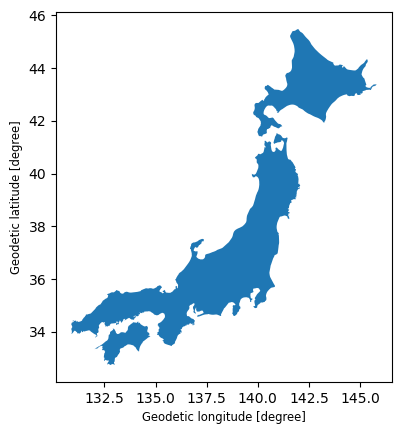

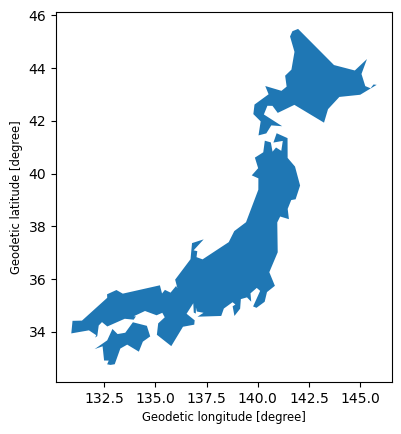

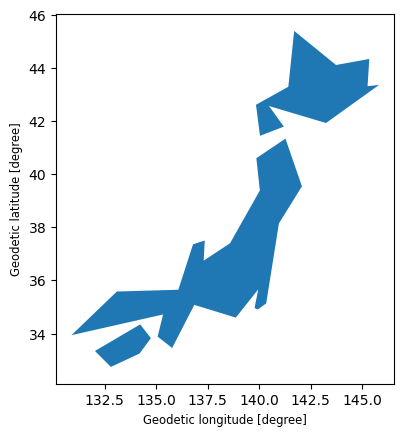

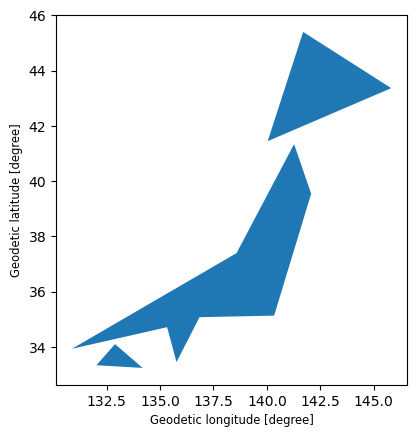

In [49]:
#ZADANIE C)

japonia = wyspy[wyspy["państwo"] == "Japonia"]
print(f"Oryginał- Liczba wierzchołków: {japonia.geometry.count_coordinates().sum()}, Liczba linii: {japonia.boundary.count_geometries().sum()}")
japonia.plot()

j1 = japonia.simplify(0.1)
j1.plot()
print(f"Uproszczenie (0.1)- Liczba wierzchołków: {j1.geometry.count_coordinates().sum()}, Liczba linii: {j1.boundary.count_geometries().sum()}")

j2 = japonia.simplify(0.5)
j2.plot()
print(f"Uproszczenie (0.5)- Liczba wierzchołków: {j2.geometry.count_coordinates().sum()}, Liczba linii: {j2.boundary.count_geometries().sum()}")

j3 = japonia.simplify(1)
j3.plot()
print(f"Uproszczenie (1)- Liczba wierzchołków: {j3.geometry.count_coordinates().sum()}, Liczba linii: {j3.boundary.count_geometries().sum()}")
